# [기초-실습] 통계 101×데이터 분석: (1-3장): 통계분석의 기초

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [20]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

In [21]:
# Vscode 환경에서 한글 폰트 설치 및 설정하기
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 설치된 한글 폰트 자동 선택 (Colab: NanumGothic / Windows: Malgun Gothic / Mac: AppleGothic)
installed = {f.name for f in fm.fontManager.ttflist}
for font in ['NanumGothic', 'Malgun Gothic', 'AppleGothic']:
    if font in installed:
        plt.rcParams['font.family'] = font  # 기본 폰트 설정
        break
else:
    print("한글 폰트를 찾지 못했습니다. Colab이라면 위 셀의 폰트 설치 명령을 실행하세요.")
print("사용 폰트:", plt.rcParams['font.family'])
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

사용 폰트: ['Malgun Gothic']


In [22]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트는 위 셀에서 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 기초통계량 계산

**📘 문제**

- 온라인 쇼핑몰 고객 1,000명을 대상으로 1점부터 10점 사이의 만족도 조사를 실시했습니다.
  이 데이터를 바탕으로 고객 만족도의 **중심 경향성**과 **분포 특성**을 파악해 봅시다.

In [23]:
# 데이터 생성
np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

**📌 아래를 수행해 보세요:**

- 평균, 중앙값, 최빈값, 표준편차를 계산해 봅시다.
- 히스토그램을 그리고 평균과 중앙값 선으로 표시해 봅시다.
- 데이터의 분포 형태를 해석한 후, 마케팅 전략 수립에 어떻게 활용할 수 있을지 생각해 봅시다.

======== 기술통계량 ========
평균     : 7.43
중앙값   : 7.42
최빈값   : 10.00
표준편차 : 1.39
왜도     : -0.17


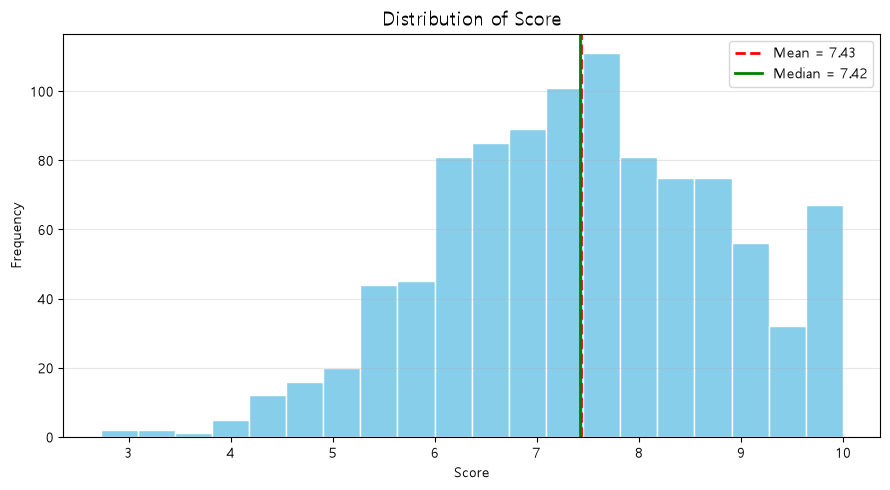


분포 형태: 오른쪽 꼬리가 긴 분포 (양의 왜도): 일부 높은 점수가 평균을 끌어올림


In [24]:
# 아래를 수행해 보세요:
# [문제 1] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

score = df1['score']

# 1. 기술통계량
mean_val = score.mean()
median_val = score.median()
mode_val = score.mode()[0]
std_val = score.std()
skew_val = score.skew()

print("======== 기술통계량 ========")
print(f"평균     : {mean_val:.2f}")
print(f"중앙값   : {median_val:.2f}")
print(f"최빈값   : {mode_val:.2f}")
print(f"표준편차 : {std_val:.2f}")
print(f"왜도     : {skew_val:.2f}")

# 2. 히스토그램 + 평균/중앙값 선
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(score, bins=20, color='skyblue', edgecolor='white')
ax.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_val:.2f}')
ax.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median = {median_val:.2f}')
ax.set_title('Distribution of Score', fontsize=14)
ax.set_xlabel('Score')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 3. 분포 형태 판단
if mean_val > median_val:
    shape = "오른쪽 꼬리가 긴 분포 (양의 왜도): 일부 높은 점수가 평균을 끌어올림"
elif mean_val < median_val:
    shape = "왼쪽 꼬리가 긴 분포 (음의 왜도): 일부 낮은 점수가 평균을 끌어내림"
else:
    shape = "대칭에 가까운 분포"
print(f"\n분포 형태: {shape}")

**🧠 데이터를 어떻게 읽을까요?**

1. 평균과 중앙값 사이의 차이는 어느 정도인가요?
   - 두 값이 비슷하다면, 이 데이터는 어떤 분포 형태일 가능성이 있을까요? (예: 대칭형, 정규분포 등)
   - 두 값의 차이가 크다면, 그 이유는 무엇일까요?
   - 어떤 값들이 평균을 끌어내리거나 끌어올렸을까요?

2. 최빈값이 평균보다 낮은 경우, 낮은 점수를 준 고객이 많다는 뜻일 수 있습니다. 이 경우 데이터 분포는 어느 쪽으로 치우쳐 있을까요?
   - 반대로 최빈값이 평균보다 높은 경우에는 어떤 해석이 가능할까요? 이럴 때 분포가 어떻게 달라질 수 있을까요?

3. 이 데이터를 바탕으로 고객 만족도를 높이기 위한 마케팅 전략에는 어떤 것들이 있을까요?

In [25]:
# 데이터를 어떻게 읽을까요?
# [문제 1] 의견

# ───────────────────────────────────────────────
# 1. 평균과 중앙값의 차이
# ───────────────────────────────────────────────
# - 이번 데이터는 평균과 중앙값의 차이가 작고(왜도도 0에 가까움),
#   히스토그램이 가운데가 높은 종 모양이므로 대칭형, 정규분포에 가까운 분포로 볼 수 있다.
# - 두 값의 차이가 크다면 분포가 한쪽으로 치우쳤다는 신호다.
#   평균은 모든 값을 더해 계산하므로 극단값의 영향을 크게 받지만,
#   중앙값은 순서상 가운데 값이라 극단값에 거의 흔들리지 않는다.
#   · 평균 > 중앙값: 꼬리 쪽의 매우 높은 점수들이 평균을 끌어올림
#   · 평균 < 중앙값: 꼬리 쪽의 매우 낮은 점수들이 평균을 끌어내림
# - 따라서 치우친 분포에서는 평균보다 중앙값이 '보통 고객'을 더 잘 대표한다.

# ───────────────────────────────────────────────
# 2. 최빈값과 평균의 관계
# ───────────────────────────────────────────────
# - 최빈값 < 평균 → 오른쪽 꼬리가 긴 분포(양의 왜도)
#   · 다수의 고객이 낮은 점수 구간에 몰려 있고,
#     소수의 높은 점수가 평균을 끌어올린 상태다.
#   · 일반적으로 '최빈값 < 중앙값 < 평균' 순서가 나타난다.
# - 최빈값 > 평균 → 왼쪽 꼬리가 긴 분포(음의 왜도)
#   · 다수의 고객은 높은 점수를 줬지만,
#     소수의 매우 낮은 점수(강한 불만)가 평균을 끌어내린 상태다.
#   · 일반적으로 '평균 < 중앙값 < 최빈값' 순서가 나타난다.
#   · 평균만 보면 만족도를 실제보다 낮게 해석할 위험이 있다.

# ───────────────────────────────────────────────
# 3. 고객 만족도를 높이기 위한 마케팅 전략
# ───────────────────────────────────────────────
# [분포 형태별 전략]
# - 오른쪽 꼬리 분포(다수가 저만족)
#   · 문제는 일부가 아닌 전반에 있으므로 제품·서비스 자체의 개선이 우선이다.
#   · 전체 대상 프로모션과 경험 개선 캠페인을 진행한다.
#   · 꼬리의 소수 고만족 고객은 리뷰·추천 프로그램으로 충성 고객화한다.
# - 왼쪽 꼬리 분포(다수 만족, 소수 강한 불만)
#   · 전체 전략은 유지하되, 저점수 고객을 타깃으로 원인 조사와 A/S, 보상을 집중한다.
#   · 강한 불만 고객은 부정 리뷰와 이탈로 이어지기 쉬우므로 빠른 대응이 중요하다.
#
# [이번 데이터(대칭형)에 대한 전략]
# - 평균 ± 1 표준편차를 기준으로 고객을 세 그룹으로 나눈다.
#   · 저만족 그룹(평균 - 1σ 미만): 설문·VOC로 불만 원인을 파악하고 개선, 재구매 쿠폰 제공
#   · 중간 그룹(평균 ± 1σ): 가장 큰 집단이므로 작은 개선으로도 전체 평균을 끌어올릴 수 있음.
#     멤버십 혜택, 맞춤 추천으로 만족도를 한 단계 올린다.
#   · 고만족 그룹(평균 + 1σ 초과): 로열티 프로그램, 추천인 리워드로 유지하고 입소문 채널로 활용
# - 전략 실행 후 같은 지표(평균, 중앙값, 표준편차)를 다시 측정해 효과를 검증한다.
#   이때 A/B 테스트로 전략 적용 그룹과 미적용 그룹을 비교하면 효과를 객관적으로 확인할 수 있다.

======== 평균, 중앙값, 표준편차 ======== 

           score
mean    7.428690
median  7.421731
std     1.392671

최빈값: 10.0

======== 'score' 히스토그램 ======== 



<Axes: >

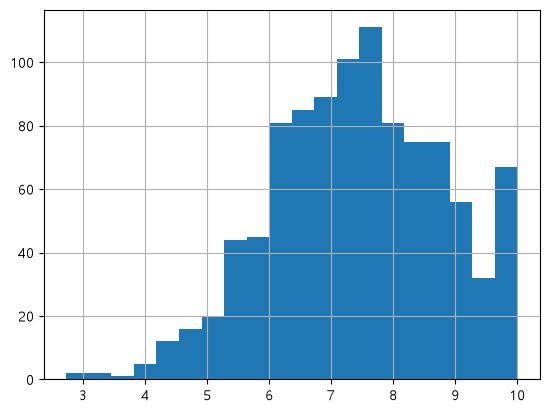

In [26]:
# 아래를 수행해 보세요:
# [문제 1] 여기에 코드를 작성해주세요.

print(f"======== 평균, 중앙값, 표준편차 ======== \n")

print(df1.agg(
    mean = ('score','mean'),
    median = ('score','median'),
    std = ('score','std'),     
))
print(f'\n최빈값: {df1["score"].mode()[0]}')
print()

print(f"======== 'score' 히스토그램 ======== \n")


df1['score'].hist(bins=20)

# 문제 2. 평균 vs 중앙값 비교

**📘 문제**

- A지역과 B지역의 연봉 데이터를 비교해 봅시다.
- B 지역에는 일부 고소득자가 포함되어 있습니다.

In [27]:
# 데이터 생성
np.random.seed(2025)

# A 지역: 평균 300, 표준편차 50
region_a = np.random.normal(300, 50, 100)

# B 지역: 일반 소득자 + 극단적인 고소득자 포함
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**📌 아래를 수행해 보세요:**

- 각 지역의 평균 연봉과 중앙값을 구해 봅시다.
- 지역별 박스플롯(Boxplot)을 그려서 분포의 차이를 시각적으로 확인해 봅시다.

======== 지역별 연봉 요약 (중앙값 내림차순) ========
        count   mean  median    std    min     max  mean_minus_median
region                                                               
A         100  292.5   294.3   46.5  189.4   407.3               -1.8
B         100  347.6   287.3  290.4  189.6  1709.9               60.2


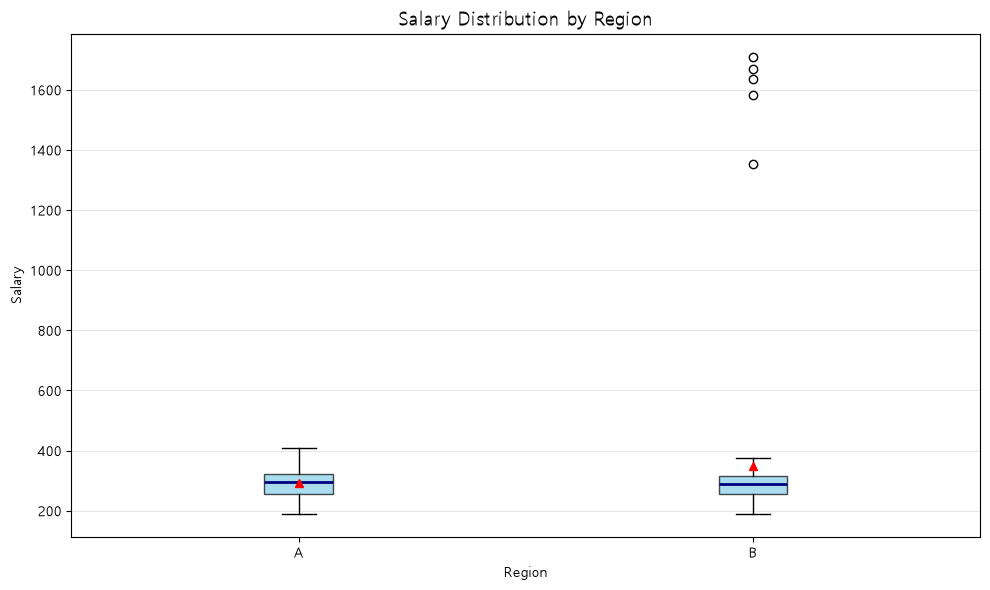


======== 지역별 분포 치우침 ========
A: 평균 < 중앙값 → 저연봉 극단값이 평균을 끌어내림 (왼쪽 꼬리)
B: 평균 > 중앙값 → 고연봉 극단값이 평균을 끌어올림 (오른쪽 꼬리)


In [28]:
# 아래를 수행해 보세요:
# [문제 2] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 1. 지역별 기술통계량
summary = (
    df2.groupby('region')['salary']
       .agg(count='count', mean='mean', median='median', std='std', min='min', max='max')
)
summary['mean_minus_median'] = summary['mean'] - summary['median']
summary = summary.sort_values('median', ascending=False)

print("======== 지역별 연봉 요약 (중앙값 내림차순) ========")
print(summary.round(1))

# 2. 지역별 박스플롯 (평균은 빨간 삼각형으로 표시)
regions = summary.index.tolist()
data = [df2.loc[df2['region'] == r, 'salary'] for r in regions]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(
    data,
    tick_labels=regions,
    showmeans=True,
    patch_artist=True,
    boxprops=dict(facecolor='skyblue', alpha=0.7),
    medianprops=dict(color='navy', linewidth=2),
    meanprops=dict(marker='^', markerfacecolor='red', markeredgecolor='red'),
)
ax.set_title('Salary Distribution by Region', fontsize=14)
ax.set_xlabel('Region')
ax.set_ylabel('Salary')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 3. 평균-중앙값 차이로 치우침 확인
print("\n======== 지역별 분포 치우침 ========")
for region, row in summary.iterrows():
    if row['mean_minus_median'] > 0:
        note = "평균 > 중앙값 → 고연봉 극단값이 평균을 끌어올림 (오른쪽 꼬리)"
    elif row['mean_minus_median'] < 0:
        note = "평균 < 중앙값 → 저연봉 극단값이 평균을 끌어내림 (왼쪽 꼬리)"
    else:
        note = "평균 ≈ 중앙값 → 대칭에 가까움"
    print(f"{region}: {note}")

**🧠 데이터를 어떻게 읽을까요?**

1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?
   - 두 지역의 평균 차이가 의미하는 바는 무엇인가요?
   - 고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?

2. 중앙값은 어떠한가요?
   - 평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?
   - 평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?
   - 이상치(Outlier)는 어떻게 표시되나요?
   - 두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?

5. 평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
   - 어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?

In [29]:
# 데이터를 어떻게 읽을까요?
# [문제 2] 의견

# ───────────────────────────────────────────────
# 1. A 지역과 B 지역의 평균 연봉 비교
# ───────────────────────────────────────────────
# - B 지역의 평균 연봉이 A 지역보다 높다.
# - 하지만 이는 B 지역 전체의 소득 수준이 높아서라기보다,
#   소수(5명)의 고소득자가 평균을 크게 끌어올린 결과로 볼 수 있다.
# - 평균은 모든 값의 합을 인원수로 나누므로, 고소득자가 있는 지역은
#   그 몇 명의 영향만으로도 평균이 실제 '보통 사람'의 소득보다 높게 나타난다.

# ───────────────────────────────────────────────
# 2. 중앙값 비교와 해석
# ───────────────────────────────────────────────
# - A 지역: 평균 ≈ 중앙값 → 대칭에 가까운 분포
# - B 지역: 평균 > 중앙값 → 오른쪽 꼬리가 긴 분포(양의 왜도)
#   · 꼬리 쪽 고소득자가 평균만 끌어올리고 중앙값은 거의 움직이지 않았다.
# - 두 지역의 중앙값은 비슷하거나 오히려 B가 약간 낮다.
#   → 일반 소득자 기준으로는 B 지역이 더 잘 산다고 보기 어렵다.
# - 일반 해석
#   · 중앙값 < 평균: 소수의 높은 값이 평균을 끌어올림
#   · 중앙값 > 평균: 소수의 낮은 값이 평균을 끌어내림

# ───────────────────────────────────────────────
# 3. 극단값(고소득자)의 영향
# ───────────────────────────────────────────────
# - 극단값의 영향은 B 지역, 그리고 그중에서도 '평균'에서 크게 나타난다.
# - 평균은 값의 크기를 그대로 반영하므로 극단값에 민감하다.
# - 중앙값은 순서상 가운데 값이므로, 극단값이 얼마나 크든 거의 영향을 받지 않는다(강건한 지표).
# - 표준편차도 평균을 기준으로 계산하므로, 고소득자가 있는 B 지역에서 더 크게 나타난다.

# ───────────────────────────────────────────────
# 4. 박스플롯 관찰
# ───────────────────────────────────────────────
# - 이상치 표시: 상자 경계에서 1.5 × IQR을 벗어난 값이 수염 바깥의 점(o)으로 표시된다.
#   · B 지역 위쪽에 따로 떨어진 점들이 고소득자 5명이다.
# - 분포 폭(IQR = Q3 - Q1, 상자 높이): 두 지역이 비슷하다.
#   → 가운데 50% 사람들의 소득 분포는 두 지역이 거의 같다.
# - 즉 두 지역의 차이는 '대다수의 소득'이 아니라 '소수의 극단값'에서 비롯된다.

# ───────────────────────────────────────────────
# 5. 평균만 보고 판단할 때의 오해
# ───────────────────────────────────────────────
# - 평균만 보면 "B 지역 사람들이 전반적으로 소득이 높다"고 잘못 결론 내릴 수 있다.
# - 실제로는 대다수의 소득은 A와 비슷하고, 소수의 고소득자만 다를 뿐이다.
# - 중앙값이 더 유용한 경우
#   · 소득, 자산, 집값처럼 소수의 극단값이 존재하는 데이터
#   · 분포가 한쪽으로 치우친(비대칭) 데이터
#   · '전형적인 한 사람'의 수준을 알고 싶을 때
# - 따라서 데이터를 요약할 때는 평균과 중앙값을 함께 보고,
#   박스플롯이나 히스토그램으로 분포 모양까지 확인하는 것이 바람직하다.

# ───────────────────────────────────────────────
# 6. IQR로 이상치를 제거한 뒤 A/B 비교
# ───────────────────────────────────────────────
# - A 지역은 IQR 기준 이상치가 없어 제거 전후가 같다. (평균 292.5, 중앙값 294.3)
# - B 지역은 고소득자 5명(약 1,354 ~ 1,710)이 모두 이상치로 제거되었다.
#   · 평균: 347.6 → 282.2 (약 65 감소)
#   · 중앙값: 287.3 → 284.2 (거의 변화 없음)
#   · 표준편차: 290.4 → 39.4 (약 7분의 1로 감소)
# - 제거 전에는 평균 기준 B가 A보다 약 55 높았지만,
#   제거 후에는 오히려 B가 A보다 약 10 낮다. → 순위가 뒤집힌다.
# - 중앙값은 제거 전에도 A(294.3) > B(287.3)였으므로,
#   이상치를 지우지 않아도 중앙값만 봤다면 같은 결론을 얻을 수 있었다.
# - 단, 고소득자 5명은 오류가 아니라 실제 존재하는 사람이므로 무조건 지우면 안 된다.
#   '일반 소득자의 수준'을 비교하려면 제거 후 값이나 중앙값을,
#   '지역 전체의 소득 총량'을 보려면 제거 전 평균을 쓰는 등 목적에 맞게 골라야 한다.


======== 지역별 임금 데이터 프레임 ======== 

region
A    100
B    100
Name: count, dtype: int64

       salary                                                              \
        count        mean         std         min         25%         50%   
region                                                                      
A       100.0  292.506637   46.520667  189.416540  256.518603  294.324483   
B       100.0  347.594909  290.417556  189.586396  254.213450  287.347488   

                                 
               75%          max  
region                           
A       322.196580   407.349329  
B       314.529178  1709.906631  

======== 평균, 중앙값, 표준편차 ======== 

              mean      median         std
region                                    
A       292.506637  294.324483   46.520667
B       347.594909  287.347488  290.417556

======== 지역별 임금 상자 그림 ======== 

======== IQR 이상치 제거 후 지역별 임금 ======== 

제거된 이상치:
    region  salary
195      B  1668.5
196      B  1581.1
197      B

<Axes: title={'center': 'salary'}, xlabel='region'>

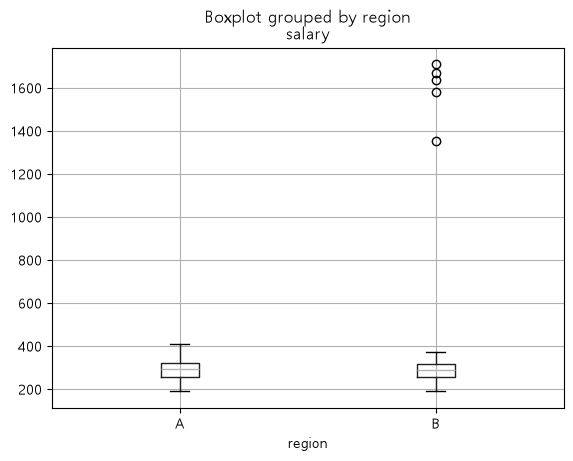

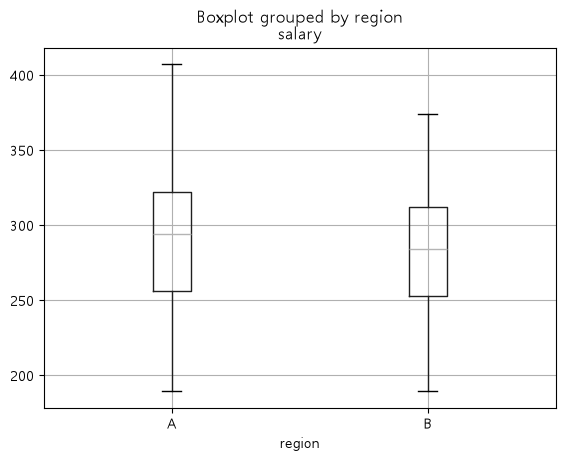

In [30]:
# 아래를 수행해 보세요:
# [문제 2] 여기에 코드를 작성해주세요.

print(f"======== 지역별 임금 데이터 프레임 ======== \n")

print(df2.value_counts("region"))
print()

print(df2.groupby("region").describe())
print()

print(f"======== 평균, 중앙값, 표준편차 ======== \n")

print(df2.groupby("region")
      .agg(
          mean = ('salary','mean'),
          median = ('salary','median'),
          std = ('salary','std'),     
))
print()

print(f"======== 지역별 임금 상자 그림 ======== \n")

df2.boxplot(column='salary', by='region')

print(f"======== IQR 이상치 제거 후 지역별 임금 ======== \n")

q1 = df2.groupby('region')['salary'].transform(lambda s: s.quantile(0.25))
q3 = df2.groupby('region')['salary'].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

df2_iqr = df2[(df2['salary'] >= q1 - 1.5 * iqr) & (df2['salary'] <= q3 + 1.5 * iqr)]

print("제거된 이상치:")
print(df2.loc[~df2.index.isin(df2_iqr.index)].round(1))
print()

print(df2_iqr.value_counts("region"))
print()

print(f"======== 제거 전 vs 제거 후 평균, 중앙값, 표준편차 ======== \n")

compare = pd.concat({
    '제거 전': df2.groupby("region")['salary'].agg(['mean', 'median', 'std']),
    '제거 후': df2_iqr.groupby("region")['salary'].agg(['mean', 'median', 'std']),
}, axis=1)
print(compare.round(1))
print()

print(f"======== 이상치 제거 후 지역별 임금 상자 그림 ======== \n")

df2_iqr.boxplot(column='salary', by='region')


# 문제 3. 이상값과 분산 비교

**📘 문제**

- 1반과 2반의 시험 점수 분포를 비교해 봅시다.
- 2반에는 극단적인 이상값(예: 부정행위로 0점)이 포함되어 있습니다.

In [31]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**📌 아래를 수행해 보세요:**

1. 각 반의 평균, 표준편차, 최소/최대값을 계산해 봅시다.
2. 박스플롯을 사용하여 두 반의 분포 차이를 시각적으로 비교해 봅시다.
3. 이상값이 통계 지표에 어떤 영향을 주는지 생각해 봅시다.

======== 반별 점수 데이터 확인 ========
class
1반    30
2반    30
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   class   60 non-null     str    
 1   score   60 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.3 KB

======== 반별 점수 요약 ========
       count   mean  median    std    min     max
class                                            
1반        30  75.72   74.75   7.06  60.69   92.18
2반        30  73.73   73.00  22.34   0.00  130.00


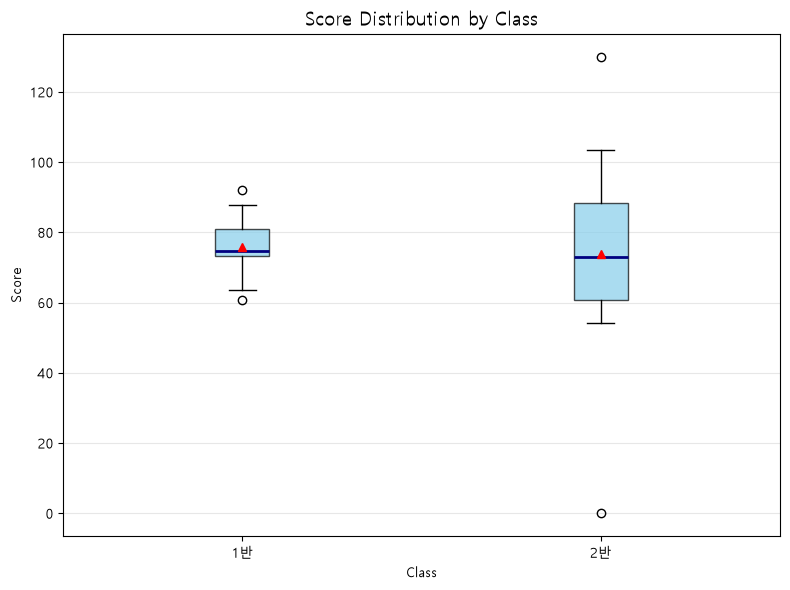


======== 반별 이상값 및 영향 ========
[1반] 이상값 기준: 62.18 미만 또는 92.04 초과
  이상값 2개: [92.17589258628496, 60.68541562198489]
  평균     75.72 → 75.67 (제거 후)
  중앙값   74.75 → 74.75 (제거 후)
  표준편차 7.06 → 5.93 (제거 후)

[2반] 이상값 기준: 19.33 미만 또는 129.79 초과
  이상값 2개: [0.0, 130.0]
  평균     73.73 → 74.35 (제거 후)
  중앙값   73.00 → 73.00 (제거 후)
  표준편차 22.34 → 14.73 (제거 후)



In [32]:
# 아래를 수행해 보세요:
# [문제 3] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 0. 데이터 확인
print("======== 반별 점수 데이터 확인 ========")
print(df3['class'].value_counts())
print()
df3.info()
print()

# 1. 반별 기술통계량
summary = df3.groupby('class')['score'].agg(
    count='count', mean='mean', median='median', std='std', min='min', max='max'
)
print("======== 반별 점수 요약 ========")
print(summary.round(2))

# 2. 반별 박스플롯 (평균은 빨간 삼각형으로 표시)
classes = summary.index.tolist()
data = [df3.loc[df3['class'] == c, 'score'] for c in classes]

fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(
    data,
    tick_labels=classes,
    showmeans=True,
    patch_artist=True,
    boxprops=dict(facecolor='skyblue', alpha=0.7),
    medianprops=dict(color='navy', linewidth=2),
    meanprops=dict(marker='^', markerfacecolor='red', markeredgecolor='red'),
)
ax.set_title('Score Distribution by Class', fontsize=14)
ax.set_xlabel('Class')
ax.set_ylabel('Score')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 3. 이상값 탐지(IQR 기준) 및 제거 전후 비교
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("\n======== 반별 이상값 및 영향 ========")
for c in classes:
    s = df3.loc[df3['class'] == c, 'score']
    low, high = iqr_bounds(s)
    outliers = s[(s < low) | (s > high)]
    trimmed = s[(s >= low) & (s <= high)]

    print(f"[{c}] 이상값 기준: {low:.2f} 미만 또는 {high:.2f} 초과")
    print(f"  이상값 {len(outliers)}개: {outliers.tolist()}")
    print(f"  평균     {s.mean():.2f} → {trimmed.mean():.2f} (제거 후)")
    print(f"  중앙값   {s.median():.2f} → {trimmed.median():.2f} (제거 후)")
    print(f"  표준편차 {s.std():.2f} → {trimmed.std():.2f} (제거 후)")
    print()

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
   - 점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
   - 이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?
   - 극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
   - 평균과 중앙값의 차이가 의미하는 바는 무엇인가요?

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?
   - 이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
   - 두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?
   - 예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
   - 중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?

In [33]:
# 데이터를 어떻게 읽을까요?
# [문제 3] 의견

# ───────────────────────────────────────────────
# 1. 어느 반의 분산이 더 크고, 왜 그럴까?
# ───────────────────────────────────────────────
# - 2반의 분산(표준편차)이 더 크다.
# - 퍼짐 정도를 확인하는 지표
#   · 표준편차(분산): 모든 값이 평균에서 얼마나 떨어져 있는지 → 이상값에 민감
#   · 범위(최댓값 - 최솟값): 양 끝 두 값만으로 계산 → 이상값에 가장 민감
#   · 사분위 범위(IQR = Q3 - Q1): 가운데 50%만 반영 → 이상값에 강건
# - 2반에는 0점과 130점 같은 이상값이 있어 표준편차와 범위가 크게 늘어났다.
#   편차를 제곱해 더하는 분산의 특성상, 평균에서 멀리 떨어진 값 하나가 큰 영향을 준다.
# - 특히 130점은 만점(100점)을 넘는 불가능한 값이므로 입력 오류로 보고
#   원본 확인 후 수정하거나 분석에서 제외하는 등의 처리가 필요하다.

# ───────────────────────────────────────────────
# 2. 이상값이 평균에 준 영향
# ───────────────────────────────────────────────
# - 0점은 평균을 끌어내리고, 130점은 평균을 끌어올린다.
# - 두 이상값이 반대 방향에 있어 영향이 일부 상쇄되었고,
#   그 결과 평균과 중앙값의 차이가 크지 않아 겉보기에는 대칭에 가까운 분포로 보인다.
# - 평균과 중앙값의 차이는 분포의 치우침을 알려 주는 신호다.
#   · 평균 > 중앙값: 높은 극단값이 평균을 끌어올림(오른쪽 꼬리)
#   · 평균 < 중앙값: 낮은 극단값이 평균을 끌어내림(왼쪽 꼬리)
# - 하지만 이번처럼 양쪽 이상값이 상쇄되면 평균과 중앙값이 비슷해도 이상값은 존재할 수 있다.
#   → 평균-중앙값 비교만으로 이상값 유무를 판단하면 안 되고,
#     표준편차·범위·박스플롯을 함께 확인해야 한다.

# ───────────────────────────────────────────────
# 3. 박스플롯에서 이상값이 드러나는 방식
# ───────────────────────────────────────────────
# - 이상값은 박스 경계(Q1, Q3)에서 1.5 × IQR을 벗어난 값으로,
#   수염 바깥에 따로 떨어진 점(o)으로 표시된다.
# - 2반에서는 0점이 박스 아래쪽, 130점이 박스 위쪽에 멀리 떨어져 나타난다.
# - 박스(IQR)는 가운데 50%만 반영하므로 이상값의 영향을 거의 받지 않는다.
#   → 두 반의 박스 크기 차이는 표준편차 차이보다 작게 보이며,
#     이는 '대다수 학생의 점수 분포는 두 반이 크게 다르지 않다'는 뜻이다.

# ───────────────────────────────────────────────
# 4. 평균만 보고 평가할 때의 오해
# ───────────────────────────────────────────────
# - 교사가 평균만 보고 "2반이 부족하다"고 판단하면,
#   대부분의 학생은 1반과 비슷한 수준인데도 소수의 극단값 때문에 생긴 차이를
#   반 전체의 실력 차이로 오해할 수 있다.
# - 게다가 그 극단값 중 일부(130점)는 입력 오류일 가능성이 높아,
#   잘못된 데이터를 근거로 반 전체를 평가하게 될 위험도 있다.
# - 함께 봐야 할 지표
#   · 중앙값: 이상값에 흔들리지 않는 '보통 학생'의 수준
#   · 표준편차 / IQR: 학생 간 실력 편차가 얼마나 큰지
#   · 박스플롯: 이상값이 몇 개이고 어디에 있는지
# - 결론: 이상값을 먼저 점검(오류 수정 또는 별도 처리)한 뒤
#   대표값과 퍼짐을 함께 분석해야 반의 실제 모습을 정확히 판단할 수 있다.
#   또한 0점 학생처럼 실제 값인 이상값은 반 전체 평가와 별개로
#   개별 지도가 필요한 학생으로 보는 것이 바람직하다.

# 문제 4. IQR 이상값 제거

**📘 문제**

- 앞의 문제에서 2반에는 **극단적인 이상값(예: 매우 낮은 점수)**이 포함되어 있어
  통계 지표, 특히 평균에 큰 영향을 주는 것을 확인했습니다.
- 이번에는 **IQR(사분위 범위)**을 기준으로 이상값을 제거한 뒤, 이상값 제거 전후의 평균을 비교해 봅시다

<br>

**📌 아래를 수행해 보세요:**

- 2반의 점수 데이터를 대상으로 IQR 기준을 사용해 이상값을 판별하고 제거해 봅시다.
- 이상값 제거 전과 제거 후의 평균을 각각 계산해 봅시다.
- 이상값 제거가 평균에 어떤 영향을 주는지 설명해 봅시다.
- 필요하다면 중앙값과도 비교해 봅시다.

======== IQR 이상값 기준 (2반) ========
Q1 = 60.75, Q3 = 88.37, IQR = 27.61
정상 범위: 19.33 ~ 129.79
이상값 2개: [0.0, 130.0]

======== 이상값 제거 전후 비교 ========
         제거 전   제거 후   변화량
count   30.00  28.00 -2.00
mean    73.73  74.35  0.62
median  73.00  73.00  0.00
std     22.34  14.73 -7.61

평균 - 중앙값: 제거 전 0.73 → 제거 후 1.35


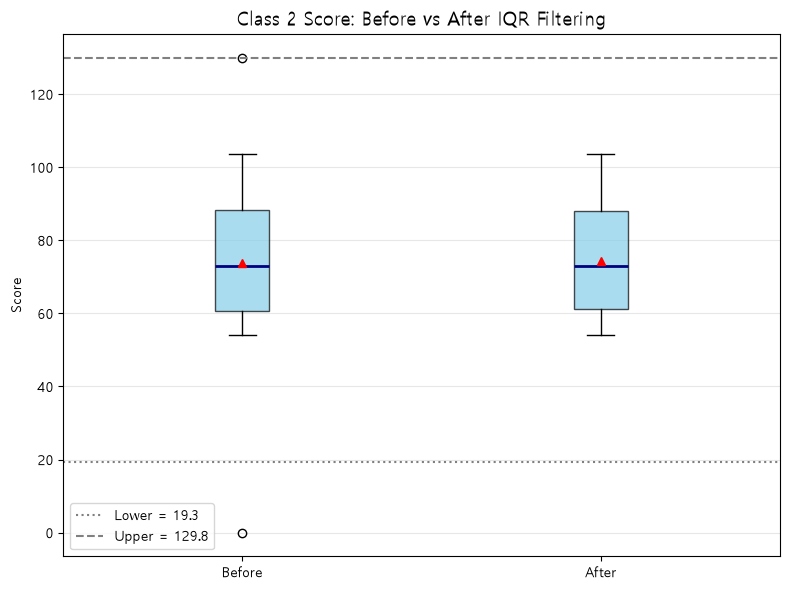

In [34]:
# 아래를 수행해 보세요:
# [문제 4] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 0. 2반 점수 추출
s = df3.loc[df3['class'] == '2반', 'score']

# 1. IQR 기준 이상값 판별
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = s[(s < lower) | (s > upper)]
s_clean = s[(s >= lower) & (s <= upper)]

print("======== IQR 이상값 기준 (2반) ========")
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"정상 범위: {lower:.2f} ~ {upper:.2f}")
print(f"이상값 {len(outliers)}개: {outliers.round(2).tolist()}")

# 2. 이상값 제거 전후 비교
compare = pd.DataFrame({
    '제거 전': s.agg(['count', 'mean', 'median', 'std']),
    '제거 후': s_clean.agg(['count', 'mean', 'median', 'std']),
})
compare['변화량'] = compare['제거 후'] - compare['제거 전']

print("\n======== 이상값 제거 전후 비교 ========")
print(compare.round(2))
print(f"\n평균 - 중앙값: 제거 전 {s.mean() - s.median():.2f} → 제거 후 {s_clean.mean() - s_clean.median():.2f}")

# 3. 제거 전후 박스플롯 (평균은 빨간 삼각형으로 표시)
fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(
    [s, s_clean],
    showmeans=True,
    patch_artist=True,
    boxprops=dict(facecolor='skyblue', alpha=0.7),
    medianprops=dict(color='navy', linewidth=2),
    meanprops=dict(marker='^', markerfacecolor='red', markeredgecolor='red'),
)
ax.set_xticks([1, 2], ['Before', 'After'])
ax.axhline(lower, color='gray', linestyle=':', label=f'Lower = {lower:.1f}')
ax.axhline(upper, color='gray', linestyle='--', label=f'Upper = {upper:.1f}')
ax.set_title('Class 2 Score: Before vs After IQR Filtering', fontsize=14)
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
   - 평균이 중앙값에 가까워졌나요?
   - 이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?

2. 왜 IQR을 기준으로 이상값을 판단할까요?
   - IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
   - 평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?

3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
   - 분석 목적에 따라 이상값은 중요한 정보가 될 수 있습니다.

4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
   - 이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
   - 두 지표를 함께 보면 어떤 장점이 있을까요?

In [35]:
# 데이터를 어떻게 읽을까요?
# [문제 4] 의견

# ───────────────────────────────────────────────
# 1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
# ───────────────────────────────────────────────
# - IQR 기준 정상 범위는 약 19.3 ~ 129.8점이며, 0점과 130점 2개가 이상값으로 제거되었다.
# - 평균: 73.73 → 74.35 (약 0.6점 상승)
#   중앙값: 73.00 → 73.00 (변화 없음)
#   표준편차: 22.34 → 14.73 (약 7.6점 감소)
# - 평균-중앙값 차이가 0.73 → 1.35로 숫자상 약간 커졌지만, 둘 다 표준편차에 비하면
#   매우 작은 차이라 평균과 중앙값이 여전히 가깝다고 볼 수 있다.
# - 평균이 올라갔다는 것은 낮은 이상값(0점, 평균에서 약 74점 아래)이
#   높은 이상값(130점, 평균에서 약 56점 위)보다 평균을 더 많이 끌어내리고 있었다는 뜻이다.
# - 가장 크게 변한 지표는 평균이 아니라 표준편차다.
#   편차를 제곱해서 더하므로 멀리 떨어진 값 두 개만 빠져도 퍼짐이 크게 줄어든다.

# ───────────────────────────────────────────────
# 2. 왜 IQR을 기준으로 이상값을 판단할까요?
# ───────────────────────────────────────────────
# - IQR(사분위 범위) = Q3 - Q1, 즉 크기순으로 정렬했을 때 가운데 50%가 차지하는 폭이다.
# - Q1 - 1.5 × IQR 보다 작거나 Q3 + 1.5 × IQR 보다 큰 값을 이상값으로 정의한다.
#   (박스플롯의 수염 바깥 점과 같은 기준)
# - 사분위수는 '순서상 위치'로 정해지므로 극단값이 아무리 커도 경계 자체가 움직이지 않는다.
# - 반면 평균 ± 3σ 기준은 이상값 때문에 평균과 표준편차가 함께 커져 기준이 넓어진다.
#   · 실제로 이 데이터에서 평균 ± 3σ는 약 6.7 ~ 140.8점이라
#     0점은 잡지만 130점(만점 초과)은 정상값으로 놓친다.
# - 따라서 IQR 기준이 이상값의 영향을 덜 받는 '강건한' 방법이다.

# ───────────────────────────────────────────────
# 3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
# ───────────────────────────────────────────────
# - 제거: 도메인상 불가능한 값, 입력·측정 오류가 확실한 값
#   · 130점은 만점(100점)을 넘으므로 오류로 보고 원본 확인 후 수정하거나 제거한다.
# - 원인 확인 후 판단: 실제로 가능한 값
#   · 0점은 결시·부정행위·실제 0점 등 가능성이 있으므로 이유를 확인한다.
#   · 부정행위로 인한 0점이라면 '실력' 평가 목적에서는 제외하는 것이 맞다.
# - 유지: 극단값이 데이터의 자연스러운 특성이거나 그 자체가 분석 대상일 때
#   · 소득·매출처럼 원래 꼬리가 긴 데이터
#   · 이상 거래 탐지, VIP 고객 분석처럼 '튀는 값'을 찾는 것이 목적인 경우
# - 무조건 제거하면 데이터가 실제보다 깔끔해 보이는 왜곡이 생기므로,
#   제거 기준과 개수를 반드시 기록해 둔다.

# ───────────────────────────────────────────────
# 4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한가요?
# ───────────────────────────────────────────────
# - 평균: 분포가 대칭에 가깝고 이상값이 없을 때 → 모든 값을 반영해 정보량이 많다.
# - 중앙값: 이상값이 있거나 한쪽으로 치우친 분포일 때 → 이번처럼 제거 전후에도 변하지 않을 만큼 강건하다.
# - 이상값이 있을 때는 중앙값이 더 신뢰할 만한 '대표값'이다.
# - 두 지표를 함께 보면
#   · 차이의 방향으로 분포가 어느 쪽으로 치우쳤는지 알 수 있고,
#   · 차이가 크면 이상값이나 치우침을 의심하는 신호로 쓸 수 있다.

# 문제 5. 변수 유형 분류

**📘 문제**

- 아래 데이터에서 변수의 유형(연속형, 범주형, 이산형 등)을 구분해 봅시다.
- 변수의 의미를 고려하여 어떤 분석 방식이 적절한지도 함께 생각해 봅시다.

In [36]:
# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

**📌 아래를 수행해 보세요:**

1. 각 변수의 데이터 타입을 확인해 봅시다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.
   - 연속형 (numeric-continuous)
   - 이산형 (numeric-discrete)
   - 범주형 (categorical)
   - 서열형 범주 (ordinal-categorical)

In [37]:
# 아래를 수행해 보세요:
# [문제 5] 여기에 코드를 작성해주세요.

# 1. 변수별 데이터 타입 확인
print("======== 변수별 데이터 타입 ========")
df5.info()
print()
display(df5.head())

# 2. 고유값 개수로 변수 성격 확인
print("\n======== 변수별 고유값 ========")
for col in df5.columns:
    uniq = df5[col].unique()
    print(f"{col:13s}: 고유값 {len(uniq):3d}개, 예시 {uniq[:5].tolist()}")

# 3. 의미 기준 변수 유형 분류
var_types = pd.DataFrame({
    'dtype': df5.dtypes.astype(str),
    'type': ['이산형', '범주형', '서열형 범주', '연속형', '서열형 범주'],
    'reason': [
        '나이를 정수(세) 단위로 셈',
        '음료 이름, 순서 없음',
        'Small < Medium < Large 순서 있음',
        '가격, 소수점까지 연속적인 값',
        '1~5점, 순서는 있으나 간격이 같다는 보장 없음',
    ],
})
print("\n======== 변수 유형 분류 ========")
display(var_types)

# 4. 서열형 변수는 순서가 있는 범주형으로 변환
df5['size'] = pd.Categorical(df5['size'], categories=['Small', 'Medium', 'Large'], ordered=True)
print("size 변환 후:", df5['size'].dtype, df5['size'].cat.categories.tolist())

======== 변수별 데이터 타입 ========
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           200 non-null    int32  
 1   coffee_type   200 non-null    str    
 2   size          200 non-null    str    
 3   price         200 non-null    float64
 4   satisfaction  200 non-null    int32  
dtypes: float64(1), int32(2), str(2)
memory usage: 9.6 KB



,age,coffee_type,size,price,satisfaction
0,48,카페모카,Small,4435.448359,1
1,36,라떼,Small,4849.195869,4
2,48,카페모카,Large,4365.135391,1
3,30,아메리카노,Medium,3979.605848,2
4,21,카페모카,Small,4650.242695,1



======== 변수별 고유값 ========
age          : 고유값  47개, 예시 [48, 36, 30, 21, 37]
coffee_type  : 고유값   3개, 예시 ['카페모카', '라떼', '아메리카노']
size         : 고유값   3개, 예시 ['Small', 'Large', 'Medium']
price        : 고유값 200개, 예시 [4435.448358571158, 4849.195869461165, 4365.13539116612, 3979.605847959412, 4650.242695240295]
satisfaction : 고유값   5개, 예시 [1, 4, 2, 3, 5]

======== 변수 유형 분류 ========


,dtype,type,reason
age,int32,이산형,나이를 정수(세) 단위로 셈
coffee_type,str,범주형,"음료 이름, 순서 없음"
size,str,서열형 범주,Small < Medium < Large 순서 있음
price,float64,연속형,"가격, 소수점까지 연속적인 값"
satisfaction,int32,서열형 범주,"1~5점, 순서는 있으나 간격이 같다는 보장 없음"


size 변환 후: category ['Small', 'Medium', 'Large']


**🧠 데이터를 어떻게 읽을까요?**

1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?

In [38]:
# 데이터를 어떻게 읽을까요?
# [문제 5] 의견

# ───────────────────────────────────────────────
# 1. 숫자처럼 보이지만 범주형·서열형으로 해석해야 하는 변수
# ───────────────────────────────────────────────
# - satisfaction(만족도)은 dtype이 int64인 숫자지만 실제로는 서열형 범주다.
#   · 1 < 2 < 3 < 4 < 5 라는 순서는 있지만,
#     1→2점과 4→5점이 같은 크기의 차이라는 보장이 없다.
#   · 따라서 평균보다 중앙값·최빈값으로 요약하는 것이 더 적절하다.
# - size는 문자열(object)이지만 Small < Medium < Large 순서가 있으므로
#   ordered Categorical로 바꿔야 정렬·비교가 올바르게 된다.
# - 그 밖에 흔한 예
#   · 성별·구매 여부(0/1), 지역 코드, 우편번호 → 숫자가 이름표 역할만 하는 범주형
#   · 학점 등급(1~5등급), 리커트 척도 → 서열형
# - 판단 기준: "이 값끼리 더하거나 평균 내는 것이 의미가 있는가?"
#   의미가 없다면 숫자로 저장돼 있어도 범주형으로 다룬다.

# ───────────────────────────────────────────────
# 2. 변수 유형에 따라 분석·시각화 방법은 어떻게 달라질까요?
# ───────────────────────────────────────────────
# - 연속형·이산형 (age, price)
#   · 요약: 평균, 중앙값, 표준편차, 사분위수
#   · 시각화: 히스토그램, 박스플롯 → 분포 모양과 이상값 확인
#   · 관계: 산점도, 상관계수, 회귀분석
# - 범주형 (coffee_type)
#   · 요약: 빈도, 비율, 최빈값
#   · 시각화: 막대그래프(countplot), 파이차트
#   · 관계: 교차표, 카이제곱 검정 / 범주별 평균 비교(t-검정, ANOVA)
# - 서열형 (size, satisfaction)
#   · 요약: 중앙값, 최빈값, 누적 비율
#   · 시각화: 범주 순서를 유지한 막대그래프
#   · 관계: 순위 기반 방법(스피어만 상관, 만-휘트니 검정 등)

# 문제 6. 상관관계 분석

**📘 문제**

- 이번에는 변수들 간의 **관계(상관관계)**를 분석해 봅시다.
- 특히 기온(`temp`), 습도(`humidity`), 판매(`sales`) 변수 간의 관계를 수치와 시각화로 살펴보겠습니다.

In [39]:
# 데이터 생성
np.random.seed(202)

temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200

df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

**📌 아래를 수행해 보세요:**

1. 아래의 기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.

2. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.

======== 상관계수 행렬 ========
          temp  humidity  sales
temp      1.00     -0.12   0.91
humidity -0.12      1.00  -0.39
sales     0.91     -0.39   1.00

======== sales와의 상관계수 ========
temp     : +0.91 (양의 상관)
humidity : -0.39 (음의 상관)


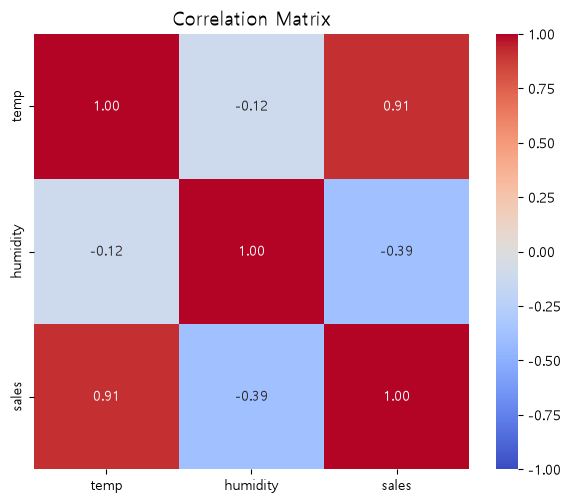

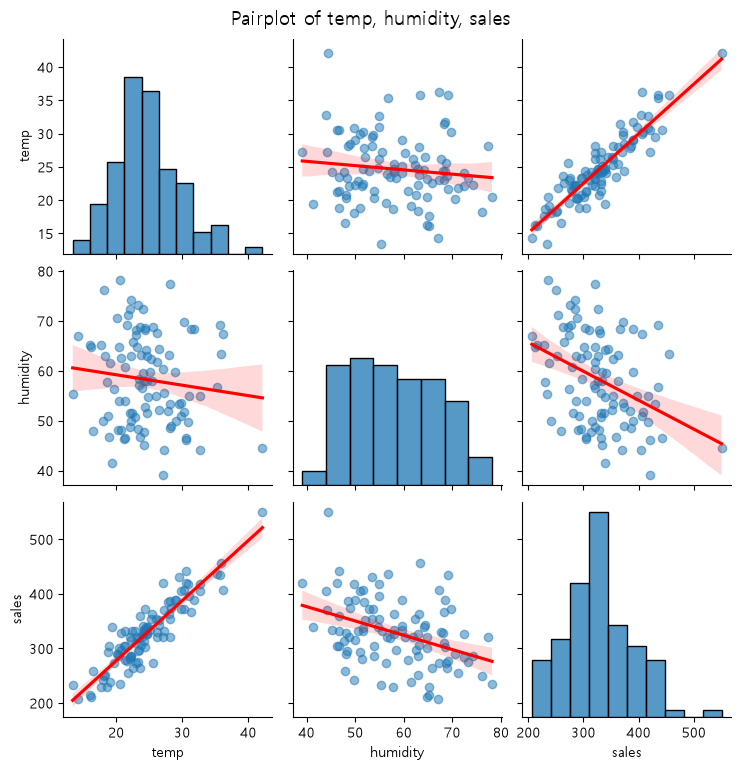

In [40]:
# 아래를 수행해 보세요:
# [문제 6] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 1. 상관계수 행렬
corr = df6.corr()
print("======== 상관계수 행렬 ========")
print(corr.round(2))

# 2. sales와의 상관계수 (절댓값이 큰 순서)
sales_corr = corr['sales'].drop('sales')
sales_corr = sales_corr.reindex(sales_corr.abs().sort_values(ascending=False).index)
print("\n======== sales와의 상관계수 ========")
for var, r in sales_corr.items():
    direction = "양의 상관" if r > 0 else "음의 상관"
    print(f"{var:9s}: {r:+.2f} ({direction})")

# 3. 상관계수 히트맵
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

# 4. 페어플롯 (회귀선 포함)
g = sns.pairplot(
    df6,
    kind='reg',
    diag_kind='hist',
    plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.5}},
)
g.fig.suptitle('Pairplot of temp, humidity, sales', y=1.02, fontsize=14)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 상관계수 행렬을 보고,
   - 어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
   - 어느 쌍이 **양의 상관관계**, 어느 쌍이 **음의 상관관계**인가요?

2. 페어플롯에서
   - 어떤 변수 쌍은 **직선 형태**로 관계가 보이나요?
   - 어떤 변수 쌍은 **분산이 크거나 패턴이 없는**가요?

3. **상관관계가 반드시 인과관계를 의미하지는 않습니다.**
   - 온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?

4. 이 데이터를 바탕으로 어떤 **추가 가설**이나 **실험 설계**를 생각해볼 수 있을까요?

In [41]:
# 데이터를 어떻게 읽을까요?
# [문제 6] 의견

# ───────────────────────────────────────────────
# 1. sales와 상관계수가 가장 높은 변수 / 양·음의 상관
# ───────────────────────────────────────────────
# - sales와 가장 상관이 높은 변수는 temp(r = 0.91)로, 매우 강한 양의 상관이다.
# - 양의 상관: temp - sales (0.91) → 기온이 높을수록 매출이 높은 경향
# - 음의 상관: humidity - sales (-0.39) → 습도가 높을수록 매출이 낮은 경향(약~중간 정도)
#              temp - humidity (-0.12) → 0에 가까워 사실상 관계가 거의 없음

# ───────────────────────────────────────────────
# 2. 페어플롯에서 보이는 패턴
# ───────────────────────────────────────────────
# - 직선 형태: temp - sales
#   · 점들이 회귀선 주변에 좁게 모여 뚜렷하게 우상향한다.
# - 분산이 크거나 패턴이 약함
#   · humidity - sales: 우하향 경향은 있지만 점들이 넓게 흩어져 있다.
#   · temp - humidity: 방향 없이 구름처럼 퍼져 있어 두 변수가 거의 독립적이다.
# - 대각선 히스토그램을 보면 세 변수 모두 종 모양에 가까워 피어슨 상관계수를 쓰기에 무리가 없다.
# - 산점도 모양과 상관계수 값이 서로 일치한다.

# ───────────────────────────────────────────────
# 3. 상관관계 ≠ 인과관계
# ───────────────────────────────────────────────
# - 상관이 높다고 해서 기온이 매출을 '직접' 올린다고 단정할 수 없다.
# - 계절·휴가철처럼 기온과 매출에 동시에 영향을 주는 제3의 요인(교란변수)이 있을 수 있다.
#   · 예: 여름에는 기온도 오르고 휴가철 유동인구도 늘어 매출이 함께 오른다.
#   · 이 경우 기온 자체의 효과는 상관계수가 보여주는 것보다 작을 수 있다.
# - 상관계수는 '직선 관계의 강도'만 나타내며, 원인과 결과의 방향은 알려주지 않는다.

# ───────────────────────────────────────────────
# 4. 추가 가설과 실험 설계
# ───────────────────────────────────────────────
# - 가설 1: 기온이 1도 오르면 매출이 일정량 증가한다.
#   → 계절·요일·휴일을 통제변수로 넣은 다중회귀로 기온의 순수 효과를 추정한다.
# - 가설 2: 습도는 기온과 별개로 매출을 낮춘다.
#   → temp와 humidity를 함께 넣은 회귀모형에서 humidity 계수가 유의한지 확인한다.
# - 가설 3: 기온과 습도의 효과는 서로 영향을 준다(덥고 습한 날은 매출이 더 떨어진다).
#   → 상호작용항(temp × humidity)을 넣어 검정한다.
# - 실험 설계: 같은 기온 조건의 매장들을 무작위로 나눠 냉방·프로모션 등 개입을 다르게 하는
#   A/B 테스트로, 기온 외 요인을 통제한 인과 효과를 확인할 수 있다.

# 문제 7. 범주형 변수 시각화

**📘 문제**

- 앞에서는 수치형 변수의 분포를 시각화하고, 변수 간의 관계도 살펴보았습니다.
- 이번에는 범주형 변수인 커피 음료 데이터를 시각화해 봅시다.
- 어떤 종류가 많이 판매되었는지 빈도 분석을 통해 알아보겠습니다.

In [42]:
# 데이터 생성
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
   - 각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
   - **막대그래프(bar plot)**를 그려서 결과를 시각화해 봅시다.

2. 시각화 결과를 보고,
   - 어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
   - 이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.

======== 데이터 확인 ========
   drink
0     라떼
1  아메리카노
2   콜드브루
3     라떼
4  아메리카노

======== 음료별 판매 빈도 ========
       count  ratio(%)
drink                 
콜드브루     108      36.0
아메리카노     97      32.3
라떼        95      31.7

총 판매량: 300잔
최다 판매: 콜드브루 (108잔) / 최소 판매: 라떼 (95잔)
1위와 최하위 차이: 13잔


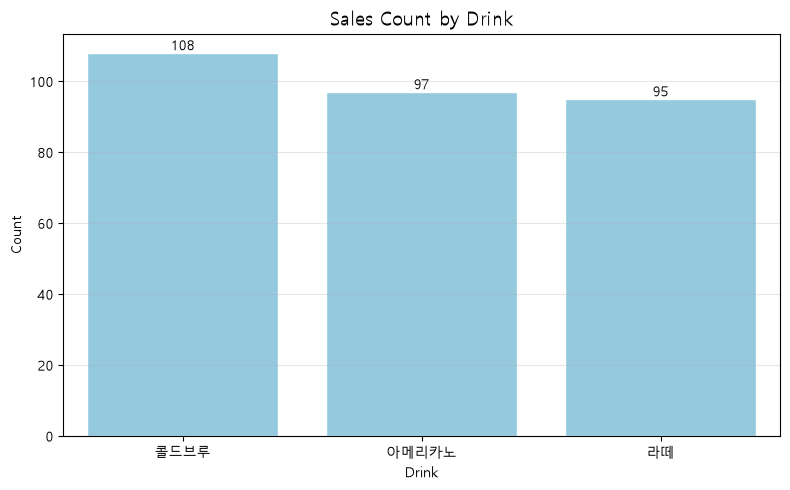

In [43]:
# 아래를 수행해 보세요:
# [문제 7] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 0. 데이터 확인
print("======== 데이터 확인 ========")
print(df7.head())
print()

# 1. 빈도표 (판매량 + 비율)
freq = df7['drink'].value_counts()
freq_table = pd.DataFrame({
    'count': freq,
    'ratio(%)': (freq / freq.sum() * 100).round(1),
})
print("======== 음료별 판매 빈도 ========")
print(freq_table)
print(f"\n총 판매량: {freq.sum()}잔")
print(f"최다 판매: {freq.idxmax()} ({freq.max()}잔) / 최소 판매: {freq.idxmin()} ({freq.min()}잔)")
print(f"1위와 최하위 차이: {freq.max() - freq.min()}잔")

# 2. 막대그래프 (판매량 순 정렬, 막대 위에 개수 표시)
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df7, x='drink', order=freq.index, color='skyblue', edgecolor='white', ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title('Sales Count by Drink', fontsize=14)
ax.set_xlabel('Drink')
ax.set_ylabel('Count')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
   - 판매량이 가장 많은 음료는?
   - 그 다음으로 인기 있는 음료는?

2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
   - 가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
   - 판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?

3. 막대그래프는 왜 범주형 변수에 적합할까요?
   - `drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?

4. 범주형 변수 분석 시 주의할 점은?

In [44]:
# 데이터를 어떻게 읽을까요?
# [문제 7] 의견
# ※ df7은 자체 시드가 없어 앞 셀 실행 순서에 따라 수치가 달라진다. (아래는 위에서부터 순서대로 실행한 기준)

# ───────────────────────────────────────────────
# 1. 가장 많이 판매된 음료와 그 다음 순위
# ───────────────────────────────────────────────
# - 1위: 콜드브루 108잔(약 36%)
# - 2위: 아메리카노 97잔(약 32%)
# - 3위: 라떼 95잔(약 32%)
# - 1위와 3위의 차이가 13잔으로 크지 않고, 아메리카노와 라떼는 거의 같은 수준이다.
# - 데이터가 세 음료를 같은 확률로 무작위 생성한 것이므로,
#   이 정도 차이는 우연(표본 변동)으로 충분히 나올 수 있다.

# ───────────────────────────────────────────────
# 2. 마케팅 전략 활용
# ───────────────────────────────────────────────
# - 주력 상품 홍보
#   · 콜드브루를 대표 메뉴로 노출을 강화할 수 있다.
#   · 다만 차이가 작으므로 한 메뉴에 '몰아주기'보다는 세 음료 모두 고른 수요가 있다고 보는 게 맞다.
# - 판매량이 적은 음료 프로모션
#   · 라떼도 수요가 없는 상품은 아니므로, 단순 할인보다는
#     디저트 세트·시즌 한정 메뉴처럼 '고를 이유'를 만들어 주는 프로모션이 효과적이다.
# - 추가 확인
#   · 콜드브루 판매가 기온·계절 영향일 수 있으므로 기간별 판매 추이를 함께 본 뒤 전략을 정한다.

# ───────────────────────────────────────────────
# 3. 막대그래프가 범주형 변수에 적합한 이유
# ───────────────────────────────────────────────
# - 서로 떨어진 범주별 값을 막대 높이로 비교하므로, 음료 종류처럼 명확히 나뉘는 변수에 적합하다.
# - 히스토그램은 x축이 연속된 수직선이라 구간 사이의 연속성을 전제로 하지만,
#   범주형 변수에는 그런 연속성이 없다. 막대 사이가 떨어져 있는 것 자체가 '다른 범주'라는 의미다.
# - 이런 변수를 분석할 때는 개수와 비율을 함께 보는 것이 중요하다.

# ───────────────────────────────────────────────
# 4. 범주형 변수 분석 시 주의할 점
# ───────────────────────────────────────────────
# - 평균·표준편차 같은 수치 연산은 의미가 없으므로 빈도, 비율, 최빈값으로 요약한다.
# - 순서가 없는 범주는 빈도순으로 정렬하면 비교가 쉽고, 서열형이면 원래 순서를 유지한다.
# - 표기만 다른 같은 범주("Coffee"/"coffee", 앞뒤 공백 등)가 따로 집계되지 않았는지 확인한다.
# - 범주별 표본 수가 적으면 순위 차이가 우연일 수 있으므로 해석에 주의한다.
#   (차이가 의미 있는지는 카이제곱 적합도 검정으로 확인할 수 있다.)

# 문제 8. 요일별 평균 비교

**📘 문제**

- 이번에는 요일 별 소비 금액 데이터를 분석해 봅시다.
- 각 요일마다 평균 소비 금액이 얼마나 되는지 비교하고,
  **평일과 주말의 소비 패턴 차이**도 함께 살펴보겠습니다.

In [45]:
# 데이터 생성
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
2. 요일별 평균 금액을 **막대그래프(bar plot)**로 시각화해 봅시다.

======== 데이터 확인 ========
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   day     500 non-null    str    
 1   amount  500 non-null    float64
dtypes: float64(1), str(1)
memory usage: 9.4 KB



,day,amount
0,수,11664.504203
1,월,15098.406430
2,수,10692.619664
3,일,11032.459859
4,화,14512.894344


======== 요일별 소비 금액 ========
     count     mean     std
day                        
월       68  11709.0  1943.0
화       62  11763.0  1983.0
수       74  12233.0  2061.0
목       84  11984.0  2077.0
금       68  11750.0  2065.0
토       74  12188.0  2113.0
일       70  11503.0  1583.0

최고: 수요일 (12,233원)
최저: 일요일 (11,503원)

======== 평일 vs 주말 ========
    count     mean     std
주말    144  11855.0  1899.0
평일    356  11900.0  2028.0
주말 - 평일 = -45원

======== 통계적 검정 ========
평일 vs 주말 t-검정: t = -0.236, p-value = 0.8136
요일별 ANOVA     : F = 1.312, p-value = 0.2497


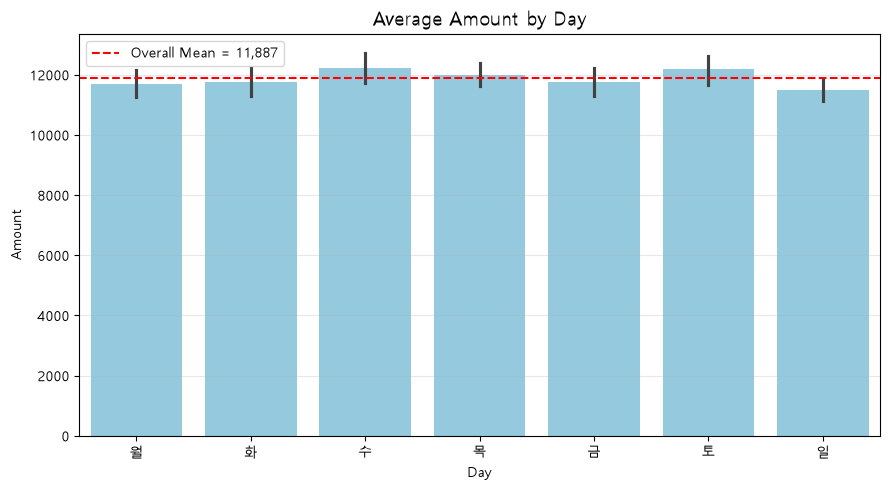

In [46]:
# 아래를 수행해 보세요:
# [문제 8] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt
from scipy import stats

day_order = ['월', '화', '수', '목', '금', '토', '일']

# 0. 데이터 확인
print("======== 데이터 확인 ========")
df8.info()
print()
display(df8.head())

# 1. 요일별 평균 소비 금액 (월~일 순서)
day_summary = (
    df8.groupby('day')['amount']
       .agg(count='count', mean='mean', std='std')
       .reindex(day_order)
)
print("======== 요일별 소비 금액 ========")
print(day_summary.round(0))
print(f"\n최고: {day_summary['mean'].idxmax()}요일 ({day_summary['mean'].max():,.0f}원)")
print(f"최저: {day_summary['mean'].idxmin()}요일 ({day_summary['mean'].min():,.0f}원)")

# 2. 평일 vs 주말 비교
day_type = np.where(df8['day'].isin(['토', '일']), '주말', '평일')
type_summary = df8.groupby(day_type)['amount'].agg(count='count', mean='mean', std='std')
print("\n======== 평일 vs 주말 ========")
print(type_summary.round(0))
print(f"주말 - 평일 = {type_summary.loc['주말', 'mean'] - type_summary.loc['평일', 'mean']:,.0f}원")

# 3. 차이가 우연인지 검정
weekday = df8.loc[day_type == '평일', 'amount']
weekend = df8.loc[day_type == '주말', 'amount']
t_stat, t_p = stats.ttest_ind(weekend, weekday, equal_var=False)
f_stat, f_p = stats.f_oneway(*[df8.loc[df8['day'] == d, 'amount'] for d in day_order])
print("\n======== 통계적 검정 ========")
print(f"평일 vs 주말 t-검정: t = {t_stat:.3f}, p-value = {t_p:.4f}")
print(f"요일별 ANOVA     : F = {f_stat:.3f}, p-value = {f_p:.4f}")

# 4. 요일별 평균 막대그래프 (오차막대 = 95% 신뢰구간)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df8, x='day', y='amount', order=day_order, color='skyblue', errorbar=('ci', 95), ax=ax)
ax.axhline(df8['amount'].mean(), color='red', linestyle='--', label=f"Overall Mean = {df8['amount'].mean():,.0f}")
ax.set_title('Average Amount by Day', fontsize=14)
ax.set_xlabel('Day')
ax.set_ylabel('Amount')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 요일에 소비 금액이 가장 높나요?
   - 주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?

2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?

3. 이 결과를 어떻게 활용할 수 있을까요?
   - 주말에 더 많은 재고를 준비하거나
   - 평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?

---

> 💬 정리해 보기
>
> - 범주형 변수(요일)별로 연속형 변수(소비 금액)의 평균을 비교하면 소비 패턴을 이해하고 전략을 수립하는 데 유용한 인사이트를 얻을 수 있습니다.

In [47]:
# 데이터를 어떻게 읽을까요?
# [문제 8] 의견
# ※ df8은 자체 시드가 없어 앞 셀 실행 순서에 따라 수치가 달라진다. (아래는 위에서부터 순서대로 실행한 기준)

# ───────────────────────────────────────────────
# 1. 소비 금액이 가장 높은 요일 / 평일 vs 주말
# ───────────────────────────────────────────────
# - 수요일 평균이 약 12,233원으로 가장 높고, 토요일(약 12,188원)이 그 다음이다.
# - 평일 평균은 약 11,900원, 주말 평균은 약 11,855원으로 오히려 평일이 약 45원 높다.
# - 하지만 표준편차(약 2,000원)에 비하면 매우 작은 차이이고,
#   t-검정 p-value = 0.81로 0.05보다 훨씬 커서 평일과 주말의 차이는 통계적으로 의미가 없다.

# ───────────────────────────────────────────────
# 2. 소비 금액이 적은 요일과 그 이유
# ───────────────────────────────────────────────
# - 일요일이 약 11,503원으로 가장 낮다.
# - 그러나 이 데이터는 모든 요일이 같은 분포(평균 12,000원, 표준편차 2,000원)에서
#   무작위로 생성되었으므로, 요일 간 차이는 실제 소비 패턴이 아니라 표본 변동(우연)이다.
#   · 가장 큰 차이(수 - 일, 약 730원)도 표준편차의 절반에 못 미친다.
#   · 막대그래프의 신뢰구간이 요일끼리 크게 겹친다.
#   · ANOVA p-value = 0.25 → '요일별 평균이 모두 같다'는 가설을 기각할 수 없다.
# - 실제 데이터라면 휴일 외식 감소, 월급일 전후 등이 원인 후보가 될 수 있지만,
#   그런 해석은 차이가 통계적으로 확인된 뒤에 해야 한다.

# ───────────────────────────────────────────────
# 3. 결과 활용 방안
# ───────────────────────────────────────────────
# - 이 데이터만으로는 요일별 소비 차이가 있다고 보기 어려우므로,
#   주말 재고 확대나 평일 할인 같은 전략을 세울 근거가 부족하다.
# - 실제 데이터에서 차이가 확인된다면
#   · 소비가 높은 요일: 재고·인력을 늘리고 객단가를 높이는 세트 상품 운영
#   · 소비가 낮은 요일: 할인 쿠폰, 포인트 적립 이벤트로 수요 분산
# - 더 긴 기간의 데이터를 모으고, 날씨·휴일 같은 요인을 함께 고려해 다시 검정하는 것이 좋다.

# 문제 9. 정규분포와 표준편차

**📘 문제**

- 정규분포와 표준편차의 개념을 실제 데이터에 적용해 보겠습니다.
- 정규분포를 따르는 점수 데이터에서 다음을 확인해 봅시다:
  - 평균 ±1σ, 평균 ±2σ 범위에 속한 값들의 비율은 실제로 얼마나 되는가?
  - 이 결과가 이론적인 68-95-99 법칙과 얼마나 유사한지 비교해 봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.

======== 생성 데이터 요약 ========
앞 5개 : [69.08 77.34 55.61 63.37 68.99]
평균   : 69.68
표준편차: 9.62

======== 68-95-99.7 법칙 비교 ========
          interval  actual(%)  theory(%)  diff(%p)
range                                             
±1σ    60.1 ~ 79.3       68.7      68.27      0.43
±2σ    50.4 ~ 88.9       95.0      95.45     -0.45
±3σ    40.8 ~ 98.5       99.6      99.73     -0.13


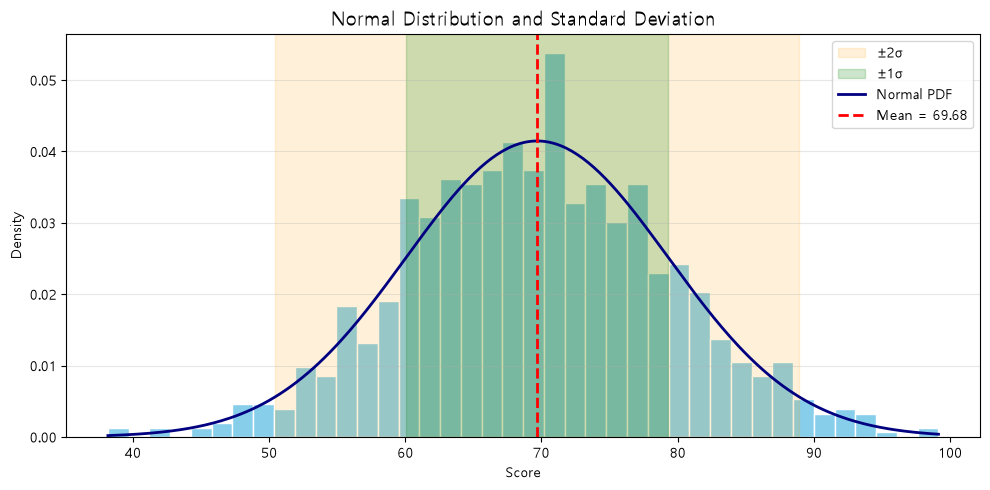

In [48]:
# 아래를 수행해 보세요:
# [문제 9] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt
from scipy import stats

# 1. 평균 70, 표준편차 10인 정규분포 데이터 1000개 생성
np.random.seed(2025)
scores = np.random.normal(70, 10, 1000)
mean_s, std_s = scores.mean(), scores.std()

print("======== 생성 데이터 요약 ========")
print(f"앞 5개 : {scores[:5].round(2)}")
print(f"평균   : {mean_s:.2f}")
print(f"표준편차: {std_s:.2f}")

# 2. ±1σ, ±2σ, ±3σ 범위에 포함되는 비율
theory = {1: 68.27, 2: 95.45, 3: 99.73}
rows = []
for k in (1, 2, 3):
    low, high = mean_s - k * std_s, mean_s + k * std_s
    ratio = ((scores >= low) & (scores <= high)).mean() * 100
    rows.append({
        'range': f'±{k}σ',
        'interval': f'{low:.1f} ~ {high:.1f}',
        'actual(%)': ratio,
        'theory(%)': theory[k],
        'diff(%p)': ratio - theory[k],
    })
result = pd.DataFrame(rows).set_index('range')

print("\n======== 68-95-99.7 법칙 비교 ========")
print(result.round(2))

# 3. 히스토그램 + 정규분포 곡선 + σ 구간 표시
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(scores, bins=40, density=True, color='skyblue', edgecolor='white')
ax.axvspan(mean_s - 2 * std_s, mean_s + 2 * std_s, color='orange', alpha=0.15, label='±2σ')
ax.axvspan(mean_s - std_s, mean_s + std_s, color='green', alpha=0.2, label='±1σ')
x = np.linspace(scores.min(), scores.max(), 300)
ax.plot(x, stats.norm.pdf(x, mean_s, std_s), color='navy', linewidth=2, label='Normal PDF')
ax.axvline(mean_s, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_s:.2f}')
ax.set_title('Normal Distribution and Standard Deviation', fontsize=14)
ax.set_xlabel('Score')
ax.set_ylabel('Density')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
3. 표준편차는 왜 중요한 지표인가요?
4. 이 개념이 실제로 어떻게 활용될 수 있을까요?

In [49]:
# 데이터를 어떻게 읽을까요?
# [문제 9] 의견

# ───────────────────────────────────────────────
# 1. ±1σ, ±2σ 범위에 실제로 몇 %가 포함되었나요?
# ───────────────────────────────────────────────
# - 생성된 데이터의 평균은 약 69.68, 표준편차는 약 9.62이다.
# - ±1σ (약 60.1 ~ 79.3점): 68.7%
# - ±2σ (약 50.4 ~ 88.9점): 95.0%
# - ±3σ (약 40.8 ~ 98.5점): 99.6%

# ───────────────────────────────────────────────
# 2. 68-95-99.7 법칙과 얼마나 비슷했나요?
# ───────────────────────────────────────────────
# - 이론값 68.27% / 95.45% / 99.73% 와 비교하면
#   차이가 각각 +0.43%p, -0.45%p, -0.13%p로 1%p 이내다.
# - 표본이 1,000개이므로 약간의 오차는 자연스럽고, 표본이 커질수록 이론값에 더 가까워진다.
# - 히스토그램도 정규분포 곡선과 잘 겹쳐, 데이터가 정규분포를 따른다는 것을 확인할 수 있다.

# ───────────────────────────────────────────────
# 3. 표준편차는 왜 중요한 지표인가요?
# ───────────────────────────────────────────────
# - 평균만으로는 알 수 없는 '퍼짐 정도'를 알려 준다.
#   · 평균이 같아도 표준편차가 크면 값들이 넓게 흩어져 있고, 작으면 평균 근처에 몰려 있다.
# - 정규분포에서는 평균과 표준편차 두 값만 알면 분포 전체가 정해진다.
#   · 특정 값이 상위 몇 %인지, 어떤 구간에 몇 %가 있는지 바로 계산할 수 있다.
# - 서로 다른 단위의 데이터도 표준화(z = (x - 평균) / σ)를 통해 같은 기준으로 비교할 수 있다.

# ───────────────────────────────────────────────
# 4. 실제 활용 사례
# ───────────────────────────────────────────────
# - 이상값 탐지: 평균 ± 3σ 밖의 값(약 0.3%)을 이상값 후보로 본다.
# - 품질 관리: 제품 규격을 평균 ± 3σ 안에 관리하는 관리도, 6시그마 기법
# - 성적·시험: 표준점수, 백분위 계산 (예: 평균 + 1σ 이상이면 상위 약 16%)
# - 금융: 수익률의 표준편차를 위험(변동성)으로 보고 투자 위험을 측정
# - 단, 데이터가 정규분포가 아니면(치우치거나 꼬리가 두꺼우면) 이 법칙이 맞지 않으므로
#   먼저 히스토그램 등으로 분포 모양을 확인해야 한다.

# 문제 10. 표본 평균 실험

**📘 문제**

- 큰 모집단에서 표본을 여러 번 추출하여 표본 평균의 분포를 비교해봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다:
   - 표본 크기 5
   - 표본 크기 50
3. 두 조건의 **표본 평균 분포(histogram)**를 비교합니다.

======== 모집단 요약 ========
모집단 크기: 100,000
평균      : 100.01
표준편차  : 15.01

======== 표본 평균 분포 비교 ========
               mean  std(SE)  theory SE(15/√n)    min     max
sample size                                                  
5            100.29     6.61              6.71  74.64  123.07
50           100.13     2.08              2.12  92.88  105.84


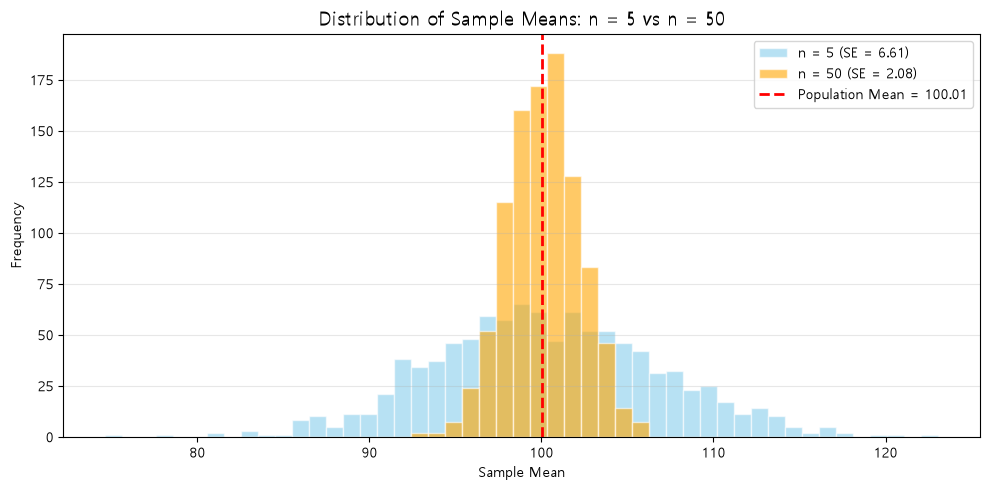

In [50]:
# 아래를 수행해 보세요:
# [문제 10] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt

# 1. 평균 100, 표준편차 15인 모집단 생성
np.random.seed(42)
population = np.random.normal(100, 15, 100_000)

print("======== 모집단 요약 ========")
print(f"모집단 크기: {len(population):,}")
print(f"평균      : {population.mean():.2f}")
print(f"표준편차  : {population.std():.2f}")

# 2. 표본 크기 5, 50으로 각각 1000번 표본 평균 계산
sample_sizes = [5, 50]
sample_means = {}
for n in sample_sizes:
    sample_means[n] = np.array([np.random.choice(population, size=n).mean() for _ in range(1000)])

summary = pd.DataFrame({
    n: {
        'mean': m.mean(),
        'std(SE)': m.std(ddof=1),
        'theory SE(15/√n)': 15 / np.sqrt(n),
        'min': m.min(),
        'max': m.max(),
    }
    for n, m in sample_means.items()
}).T
summary.index.name = 'sample size'

print("\n======== 표본 평균 분포 비교 ========")
print(summary.round(2))

# 3. 표본 평균 분포 히스토그램 비교 (같은 구간으로 겹쳐 그림)
bins = np.linspace(sample_means[5].min(), sample_means[5].max(), 50)
colors = {5: 'skyblue', 50: 'orange'}

fig, ax = plt.subplots(figsize=(10, 5))
for n in sample_sizes:
    ax.hist(sample_means[n], bins=bins, alpha=0.6, color=colors[n], edgecolor='white',
            label=f'n = {n} (SE = {sample_means[n].std(ddof=1):.2f})')
ax.axvline(population.mean(), color='red', linestyle='--', linewidth=2,
           label=f'Population Mean = {population.mean():.2f}')
ax.set_title('Distribution of Sample Means: n = 5 vs n = 50', fontsize=14)
ax.set_xlabel('Sample Mean')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. **표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?**
2. **왜 표본 크기가 중요할까요?**
3. **이 개념은 실제로 어디에 활용될 수 있을까요?**

In [51]:
# 데이터를 어떻게 읽을까요?
# [문제 10] 의견

# ───────────────────────────────────────────────
# 1. 표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?
# ───────────────────────────────────────────────
# - 두 경우 모두 표본 평균들의 평균은 모집단 평균(약 100.01)과 거의 같다.
#   · n = 5: 100.29 / n = 50: 100.13
#   → 표본 평균은 표본 크기와 관계없이 모평균을 중심으로 분포한다(불편추정량).
# - 퍼짐 정도는 크게 다르다.
#   · n = 5 : 표본 평균의 표준편차(표준오차) 약 6.61 (이론값 15/√5 ≈ 6.71)
#   · n = 50: 표본 평균의 표준편차(표준오차) 약 2.08 (이론값 15/√50 ≈ 2.12)
# - 히스토그램에서도 n = 50 쪽이 평균 근처에 훨씬 좁고 뾰족하게 모여 있다.
# - 표본 크기가 10배가 되면 표준오차는 √10 ≈ 3.2배 줄어든다.

# ───────────────────────────────────────────────
# 2. 왜 표본 크기가 중요할까요?
# ───────────────────────────────────────────────
# - 표준오차 = σ / √n 이므로, 표본이 클수록 표본 평균이 모평균에서 덜 벗어난다.
#   → 한 번의 조사로 얻은 평균을 더 믿을 수 있다.
# - 표본이 작으면 운에 따라 실제보다 크게 높거나 낮은 평균이 나올 수 있다.
#   · n = 5에서는 표본 평균이 약 80 ~ 120까지 퍼지지만, n = 50에서는 대부분 96 ~ 104 안에 있다.
# - 중심극한정리: 표본이 충분히 크면 모집단 분포와 관계없이 표본 평균의 분포가 정규분포에 가까워진다.
#   → 신뢰구간, t-검정, A/B 테스트 같은 통계적 추론의 기반이 된다.
# - 단, √n에 비례하므로 정밀도를 2배 높이려면 표본이 4배 필요하다(비용과의 균형).

# ───────────────────────────────────────────────
# 3. 실제 활용 사례
# ───────────────────────────────────────────────
# - 여론조사: 표본 크기로 오차 범위(±몇 %p)를 계산해 결과의 신뢰도를 제시한다.
# - A/B 테스트: 실험 전에 원하는 차이를 잡아낼 수 있도록 필요한 표본 크기를 미리 계산한다.
# - 품질 검사: 전수 검사 대신 일정 크기의 표본을 뽑아 불량률·평균 규격을 추정한다.
# - 임상시험: 약효 차이를 통계적으로 확인할 만큼 충분한 환자 수를 설계한다.

# 문제 11. 단순 선형 회귀 분석

**📘 문제**

- 공부 시간과 성적 간의 관계를 회귀 분석으로 확인해봅시다.

In [52]:
# 데이터 생성
from sklearn.linear_model import LinearRegression

np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

**📌 아래를 수행해 보세요:**

1. 공부 시간(`study_time`)과 성적(`score`)간의 관계를 단순 선형 회귀모델로 분석합니다.
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
3. 산점도 위에 회귀선을 시각화해 봅시다.

======== sklearn LinearRegression ========
기울기(계수): 7.9093
절편        : 51.6057
R²          : 0.9270

======== statsmodels OLS ========
회귀식: score = 51.61 + 7.91 × study_time
기울기 95% 신뢰구간: 7.46 ~ 8.35
기울기 p-value     : 1.63e-57
100점 도달 공부 시간: 6.12시간 (이후는 외삽)

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.927
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     1245.
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           1.63e-57
Time:                        23:59:18   Log-Likelihood:                -288.46
No. Observations:                 100   AIC:                             580.9
Df Residuals:                      98   BIC:                             586.1
Df Model:                           1                                         
Covariance Type:            no

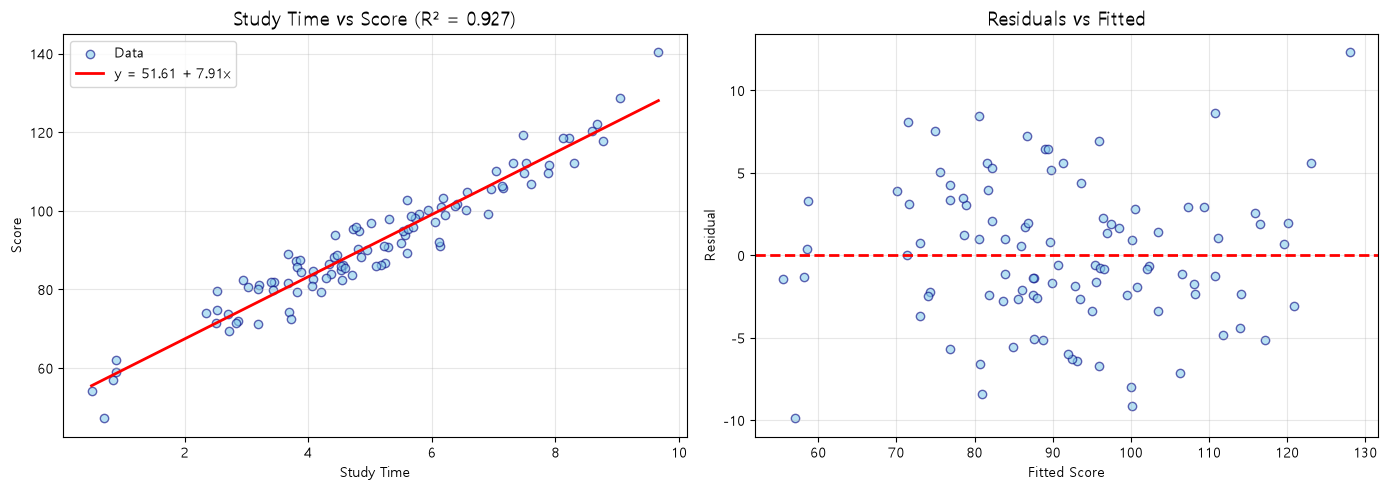

In [53]:
# 아래를 수행해 보세요:
# [문제 11] 여기에 코드를 작성해주세요.
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# 1. 단순 선형 회귀모델 학습 (sklearn)
X = df11[['study_time']]
y = df11['score']

model = LinearRegression()
model.fit(X, y)

# 2. 기울기와 절편 출력
print("======== sklearn LinearRegression ========")
print(f"기울기(계수): {model.coef_[0]:.4f}")
print(f"절편        : {model.intercept_:.4f}")
print(f"R²          : {model.score(X, y):.4f}")

# 3. statsmodels로 유의성·신뢰구간 확인
result = smf.ols('score ~ study_time', data=df11).fit()
b0, b1 = result.params['Intercept'], result.params['study_time']
ci_low, ci_high = result.conf_int().loc['study_time']

print("\n======== statsmodels OLS ========")
print(f"회귀식: score = {b0:.2f} + {b1:.2f} × study_time")
print(f"기울기 95% 신뢰구간: {ci_low:.2f} ~ {ci_high:.2f}")
print(f"기울기 p-value     : {result.pvalues['study_time']:.2e}")
print(f"100점 도달 공부 시간: {(100 - b0) / b1:.2f}시간 (이후는 외삽)")
print()
print(result.summary())

# 4. 산점도 + 회귀선 / 잔차 그래프
x_line = np.linspace(df11['study_time'].min(), df11['study_time'].max(), 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df11['study_time'], df11['score'], alpha=0.6, color='skyblue', edgecolor='navy', label='Data')
axes[0].plot(x_line, b0 + b1 * x_line, color='red', linewidth=2, label=f'y = {b0:.2f} + {b1:.2f}x')
axes[0].set_title(f'Study Time vs Score (R² = {result.rsquared:.3f})', fontsize=14)
axes[0].set_xlabel('Study Time')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(result.fittedvalues, result.resid, alpha=0.6, color='skyblue', edgecolor='navy')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residuals vs Fitted', fontsize=14)
axes[1].set_xlabel('Fitted Score')
axes[1].set_ylabel('Residual')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 공부 시간이 성적에 어떤 영향을 주었나요?
2. 회귀선은 데이터를 잘 설명하고 있나요?
3. 이 회귀식을 현실에 적용할 수 있을까요?
4. 선형 회귀분석은 언제 활용할 수 있을까요?

In [54]:
# 데이터를 어떻게 읽을까요?
# [문제 11] 의견

# ───────────────────────────────────────────────
# 1. 공부 시간이 성적에 어떤 영향을 주었나요?
# ───────────────────────────────────────────────
# - 회귀식: 성적 = 51.61 + 7.91 × 공부시간
# - 공부 시간이 1시간 많은 학생은 성적이 평균적으로 약 7.9점 높다.
#   · 기울기 95% 신뢰구간: 약 7.47 ~ 8.35점 → 0을 포함하지 않음
#   · p-value < 0.001 → 통계적으로 매우 유의한 양의 관계
# - 다만 회귀분석만으로 '공부 시간이 성적을 올렸다'는 인과관계를 증명할 수는 없다.
#   학습 의욕·기초 실력처럼 두 변수에 동시에 영향을 주는 요인이 있을 수 있으므로,
#   인과로 해석하려면 이런 변수를 통제해야 한다.

# ───────────────────────────────────────────────
# 2. 회귀선은 데이터를 잘 설명하고 있나요?
# ───────────────────────────────────────────────
# - 결정계수 R² = 0.927 → 성적 변동의 약 92.7%를 공부 시간 하나로 설명한다.
# - 잔차 진단
#   · Omnibus(p = 0.851), Jarque-Bera(p = 0.818): 잔차가 정규분포를 따른다는 가정을 기각하지 않음
#   · Durbin-Watson = 2.21: 2에 가까워 잔차 간 자기상관이 거의 없음
#   · 잔차 그래프: 0을 중심으로 고르게 흩어져 있고 뚜렷한 패턴이 없음
# - 따라서 선형 모형이 이 데이터를 잘 설명한다.

# ───────────────────────────────────────────────
# 3. 이 회귀식을 현실에 적용할 수 있을까요?
# ───────────────────────────────────────────────
# - 인과가 아닌 '관계'를 나타내므로 처방(공부 시간 강제)보다는 예측 용도로 쓰는 것이 적절하다.
# - 데이터 범위 안에서만 신뢰할 수 있다(외삽의 한계).
#   · 공부 시간이 약 6.1시간을 넘으면 예측 점수가 100점을 넘는데, 이는 현실에서 불가능하다.
#   · 실제로는 공부 시간이 늘수록 성적 증가 폭이 줄어드는 곡선 관계일 가능성이 높다.
# - 이 데이터는 직선 관계로 만들어진 가상 데이터이므로, 실제 학생 데이터는
#   설명력이 훨씬 낮고 다른 요인(수면, 학습 방법 등)이 함께 작용할 것이다.

# ───────────────────────────────────────────────
# 4. 선형 회귀분석은 언제 활용할 수 있을까요?
# ───────────────────────────────────────────────
# - 결과 변수가 연속형이고, 설명 변수와 직선에 가까운 관계일 때
# - 한 변수가 바뀔 때 다른 변수가 평균적으로 얼마나 변하는지 수치로 해석하거나 예측할 때
#   · 광고비 → 매출, 면적 → 집값, 기온 → 아이스크림 판매량
# - 주의할 점
#   · 관계가 곡선이거나 이상값이 많으면 결과가 왜곡되므로 산점도와 잔차를 함께 확인한다.
#   · 설명 변수가 여러 개라면 다중회귀로 확장하고, 변수 간 다중공선성도 점검한다.

# 문제 12. A/B 테스트 해석

**📘 문제**

- 두 그룹의 전환율 차이를 계산하고 해석해봅시다.

In [55]:
import numpy as np

group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

rate_a = group_a.mean()
rate_b = group_b.mean()
print(f"A 전환율: {rate_a:.3f}, B 전환율: {rate_b:.3f}, 차이(B-A): {rate_b - rate_a:.3f}")

A 전환율: 0.116, B 전환율: 0.172, 차이(B-A): 0.056


**📌 아래를 수행해 보세요:**

1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.

In [56]:
import numpy as np
from scipy import stats

np.random.seed(42)
group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

# 1. 데이터 살펴보기
print("A 앞 20개:", group_a[:20])
print("B 앞 20개:", group_b[:20])
print(f"A: {len(group_a)}명 중 {group_a.sum()}명 전환")
print(f"B: {len(group_b)}명 중 {group_b.sum()}명 전환")

# 2. 전환율과 차이
rate_a = group_a.mean()
rate_b = group_b.mean()
diff = rate_b - rate_a
print(f"\nA 전환율: {rate_a:.3f}, B 전환율: {rate_b:.3f}, 차이(B-A): {diff:.3f}")

# 3. 두 비율 z-검정: 차이가 우연인지 확인
n_a, n_b = len(group_a), len(group_b)
p_pool = (group_a.sum() + group_b.sum()) / (n_a + n_b)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z = diff / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"z = {z:.3f}, p-value = {p_value:.4f}")

if p_value < 0.05:
    print("유의수준 5%에서 두 그룹의 전환율 차이는 통계적으로 유의합니다.")
else:
    print("유의수준 5%에서 차이가 우연일 가능성을 배제할 수 없습니다.")

A 앞 20개: [0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0]
B 앞 20개: [0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0]
A: 1000명 중 124명 전환
B: 1000명 중 152명 전환

A 전환율: 0.124, B 전환율: 0.152, 차이(B-A): 0.028
z = 1.815, p-value = 0.0695
유의수준 5%에서 차이가 우연일 가능성을 배제할 수 없습니다.


**🧠 데이터를 어떻게 읽을까요?**

1. 두 그룹의 전환율 차이는 얼마나 되나요?
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
4. A/B 테스트는 현실에서 어떻게 쓰일까요?

In [57]:
# 데이터를 어떻게 읽을까요?
# [문제 12] 의견

# 1. 두 그룹의 전환율 차이는 얼마나 되나요?
# - A안은 약 12%, B안은 약 15% 수준으로, B가 약 3%p 높게 나왔다.
#   (정확한 값은 앞 셀에서 출력된 rate_a, rate_b, diff 값을 따른다.)
# - 상대적으로 보면 B가 A보다 약 25%(0.03 / 0.12) 더 높은 전환율이다.

# 2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
# - 표본은 무작위로 뽑히기 때문에, 두 안의 실제 효과가 같아도 전환율은 조금씩 다르게 나온다.
# - '통계적으로 의미 있다(유의하다)'는 것은 이 차이가 그런 우연한 흔들림만으로는
#   잘 나오지 않을 만큼 크다는 뜻이다.
# - 두 비율 z-검정의 p-value가 0.05보다 작으면 유의수준 5%에서 의미 있는 차이로 본다.
# - 단, 통계적 유의성과 실무적 중요성은 다르다. 차이가 유의해도 그 크기가
#   비즈니스에 영향을 줄 만큼 큰지는 따로 판단해야 한다.

# 3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
# - p-value < 0.05 이면: B안이 더 효과적이라는 근거가 있으므로 B안 도입을 고려한다.
# - p-value >= 0.05 이면: 차이가 우연일 가능성을 배제할 수 없으므로, 바로 바꾸기보다
#   표본을 더 모으거나 실험 기간을 늘려 다시 확인한다.
# - '유의하지 않다'는 '차이가 없다'는 뜻이 아니라 '이 데이터로는 확신할 수 없다'는 뜻이다.
# - 각 그룹 1000명 수준에서는 3%p 차이도 실행할 때마다 유의/비유의가 바뀔 수 있으므로,
#   실험 전에 필요한 표본 크기를 미리 계산해 두는 것이 좋다.

# 4. A/B 테스트는 현실에서 어떻게 쓰일까요?
# - 웹/앱: 버튼 색상·문구, 페이지 레이아웃, 회원가입 절차를 바꿨을 때 전환율 비교
# - 마케팅: 이메일 제목, 광고 문구·이미지에 따른 클릭률·구매율 비교
# - 커머스: 가격 표시 방식, 추천 알고리즘, 할인 정책의 매출 효과 검증
# - 서비스 개선: 새 기능 출시 전 일부 사용자에게만 먼저 적용해 효과를 확인
# - 핵심은 사용자를 무작위로 나눠 다른 조건은 같게 두고, 바꾼 요소 하나의 효과만
#   비교하는 것이다. 그래서 '느낌'이 아니라 데이터로 결정을 내릴 수 있다.